In [1]:
import os
import librosa
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression, SGDClassifier, RidgeClassifier 
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score, confusion_matrix
from sklearn.preprocessing import StandardScaler, minmax_scale
from tqdm import tqdm
from scipy.stats import skew, kurtosis 
from IPython.display import Audio
import matplotlib.pyplot as plt
import seaborn as sns


import xgboost as xgb
import lightgbm as lgb 


import warnings
warnings.filterwarnings('ignore')


In [2]:
sample_submission = pd.read_csv('/kaggle/input/ai-paradox/sample_submission.csv', index_col = 'file_name')
sample_submission

,target
file_name,
00001.wav,0
00002.wav,1
00003.wav,0
00004.wav,1
00005.wav,0
00006.wav,0
00007.wav,1
00008.wav,1
00009.wav,0


# This is the final submission for the AI Paradox Competition

## Bit of background:

So I played around a lot of settings, tweaks and libraries on the first day and didn't recieve much results using the tf.Convo2D CNN neural networks.

then I came across this dataset on Kaggle of Music Genre Classification which in no way is related to our problem but it included a csv sheet with all the different features applied (like spectral centrol, N_MFCC, spectral rolloff, chroma etc), and applying a normal ML model instead of a DL model on data like this gave more promising results.

[dataset](https://www.kaggle.com/datasets/andradaolteanu/gtzan-dataset-music-genre-classification)

## Approach:

- We first convert our audio files from 10SEC length to 1SEC segments with overlap ratio of 0.5
- then we used librosa library for audio pre-processing and taking out variance, mean, kurtosis, skewness of important features from the segments.
-  The feautures include: {RMS, ZCR, Spectral Centroid, Spectral Bandwidth, Spectral Rolloff, Spectral Flatness, MFCCs Delta, Raw MFCCs, Chroma Features}
-  Then we merge all these together and convert them to Numpy arrays so we can apply ML models to it
-  We use StandardScaler() from sklearn.preprocessing to scale the values for some of our models.
-  then we import a bunch of ML/DL models (mostly from sklearn) to compare the predictions of all the models
-  I used 7 different ML models (ensemble, regression, nearest neighbour) for the comparison.
-  For the comparison, we have 3 metrics systems; AUC_ROC, F1, and accuracy_score.
-  For training the models, We use 5-Fold Stratified Cross-Validation (CV) for reliable performance assessment and select the model based on F1 score.
-  The final prediction for each 10-second file is determined by aggregating the predictions from all its ∼19 segments.
-  After this, we do some more analysis, and determine the vote ratio.

Note: Currently the vote ratio is set at 16% which performed best for the testing dataset values (~96%), but arguably it is not fully good since of the discrepancies caught in the testing dataset.

**The discrepancies that I found in the testing dataset:**


**00019.wav - classified as Normal in the dataset, but is actually Abnormal;\
00036.wav - classified as Normal in the dataset, but is actually Abnormal;\
00052.wav - classified as Normal in the dataset, but has high probability of being Abnormal;\
00094.wav - classified as Normal in the dataset, but is actually Abnormal;\
00129.wav - classfied as Abnormal in the dataset, but has high probability of being Normal;**


it may vary depending on what GPU you use, sometimes Kfold's best model is LightGBM, other times it is XGB Classifier.

Overall XGBClassifier has been the best performing model for me


In [3]:
# --- Configuration ---
DATA_DIR = '/kaggle/input/ai-paradox/' # Change this to the path where your 'train' and 'test' folders are
SAMPLE_RATE = 22050
DURATION = 10.0 # Using the full 10-second duration
N_MELS = 128   # Number of Mel bands (Height of the image)
N_FFT = 1024     # Window size (approx 100ms for 22050 SR)
HOP_LENGTH = 256 # Hop size (Time resolution)
N_MFCC = 40
TARGET_RMS = 0.05

SEGMENT_DURATION = 1.0  # New segment length (1.0 seconds)
OVERLAP_RATIO = 0.5    # Overlap between segments (50% overlap)
SEGMENT_SAMPLES = int(SEGMENT_DURATION * SAMPLE_RATE)
HOP_SAMPLES = int(SEGMENT_SAMPLES * (1 - OVERLAP_RATIO))

TEST_DATA_DIR = '/kaggle/input/ai-paradox/test/'

TRAIN_DATA_NORMAL_DIR = '/kaggle/input/ai-paradox/train/normal/'

TRAIN_DATA_ABNORMAL_DIR = '/kaggle/input/ai-paradox/train/abnormal/'

In [4]:
labels = list(os.listdir(DATA_DIR + 'train'))
labels

['normal', 'abnormal']

In [5]:
# Lets review some Audio files 

original_audio, sr = librosa.load(TRAIN_DATA_NORMAL_DIR + '000005.wav')
print('y :', original_audio,)
print('y shape :', np.shape(original_audio))
print('Sample Rate (KHz) :', sr)
print('Time Duration :', np.shape(original_audio)[0]/sr)
print('Type : NORMAL', '\n')
Audio(data=original_audio, rate=sr)

y : [ 0.00323081  0.00081269 -0.00361122 ...  0.00187049  0.00464264
  0.00407299]
y shape : (220500,)
Sample Rate (KHz) : 22050
Time Duration : 10.0
Type : NORMAL 



In [6]:
original_audio, sr = librosa.load(TRAIN_DATA_ABNORMAL_DIR + '000005.wav')
print('y :', original_audio)
print('y shape :', np.shape(original_audio))
print('Sample Rate (KHz) :', sr)
print('Time Duration :', np.shape(original_audio)[0]/sr)
print('Type : ABNORMAL', '\n')
Audio(data=original_audio, rate=sr)

y : [-0.00353533 -0.00370149 -0.00246926 ...  0.00082064  0.00184551
  0.00146308]
y shape : (220500,)
Sample Rate (KHz) : 22050
Time Duration : 10.0
Type : ABNORMAL 



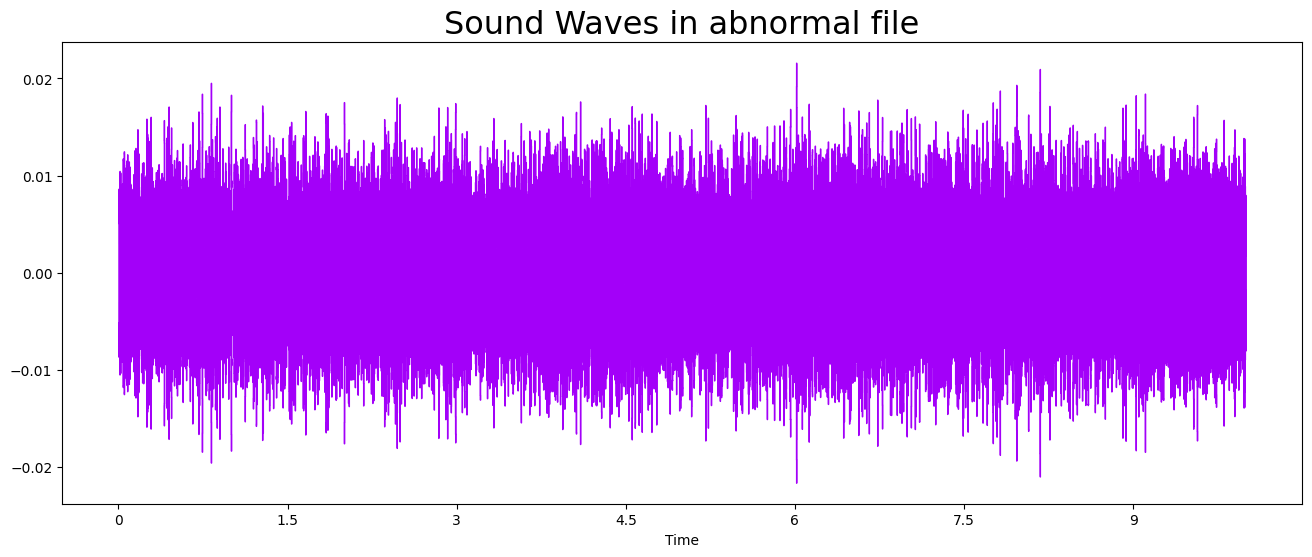

In [7]:
plt.figure(figsize = (16, 6))
librosa.display.waveshow(y = original_audio, sr = sr, color = "#A300F9");
plt.title("Sound Waves in abnormal file", fontsize = 23);

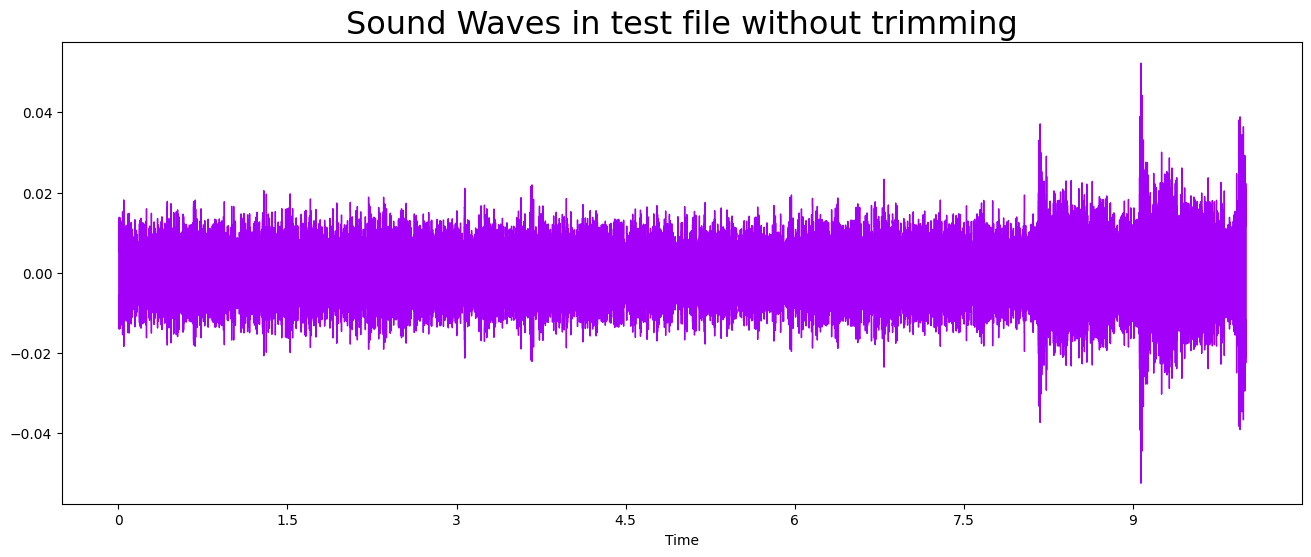

In [8]:
# Lets see another example

original_audio, sr = librosa.load(TEST_DATA_DIR + '00019.wav')
plt.figure(figsize = (16, 6))
librosa.display.waveshow(y = original_audio, sr = sr, color = "#A300F9");
plt.title("Sound Waves in test file without trimming", fontsize = 23);
Audio(data=original_audio, rate=sr)

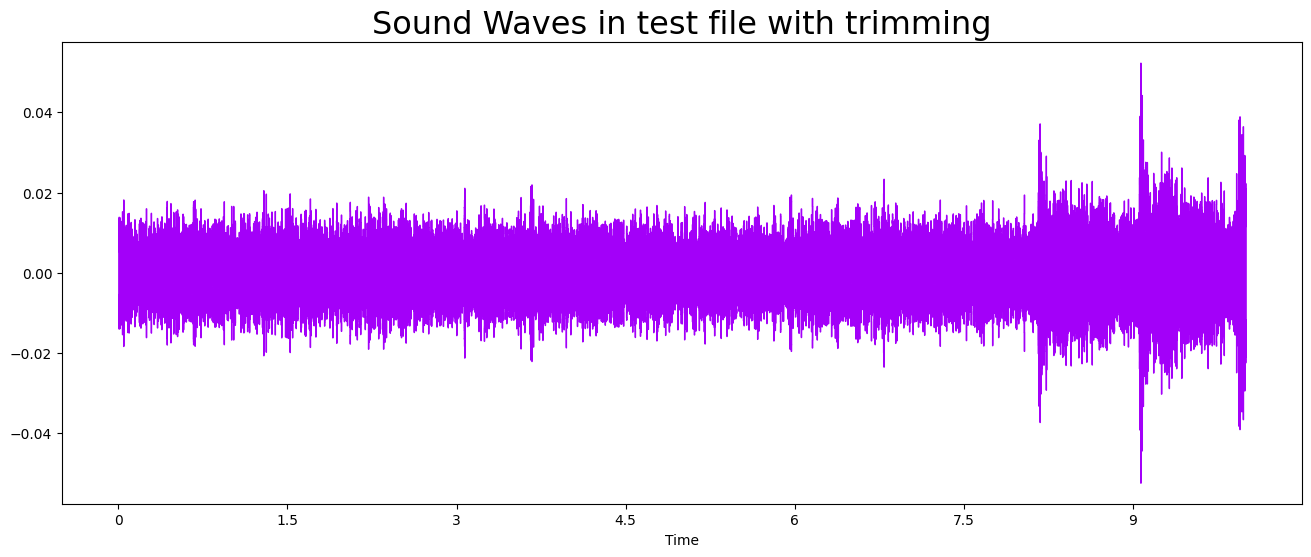

In [9]:
# Lets see another example

original_audio, sr = librosa.load(TEST_DATA_DIR + '00019.wav')
audio_file, _ = librosa.effects.trim(original_audio)
plt.figure(figsize = (16, 6))
librosa.display.waveshow(y = audio_file, sr = sr, color = "#A300F9");
plt.title("Sound Waves in test file with trimming", fontsize = 23);
Audio(data=audio_file, rate=sr)

In [10]:
# Short-time Fourier transform (STFT)
D = np.abs(librosa.stft(audio_file, n_fft=N_FFT, hop_length=HOP_LENGTH))

print('Shape of D object:', np.shape(D))

Shape of D object: (513, 862)


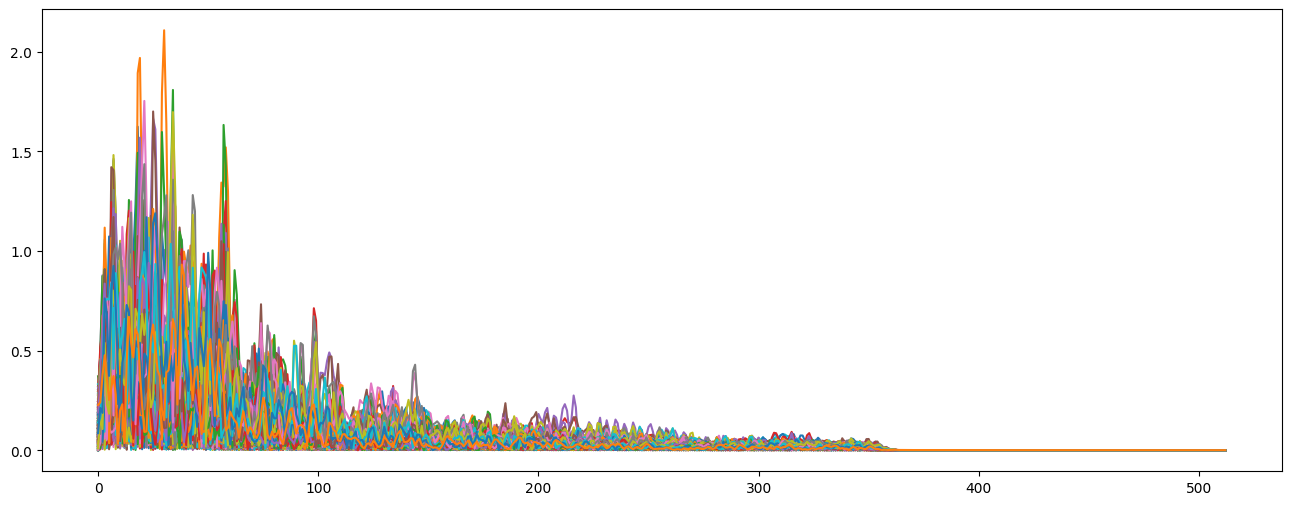

In [11]:
plt.figure(figsize = (16, 6))
plt.plot(D);

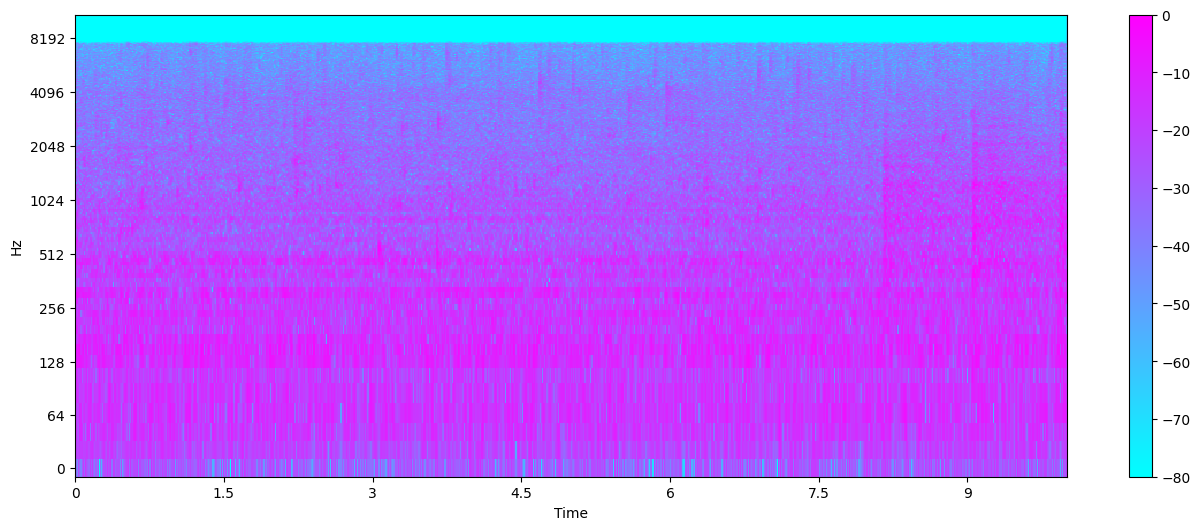

In [12]:
# Convert an amplitude spectrogram to Decibels-scaled spectrogram.
DB = librosa.amplitude_to_db(D, ref = np.max)

# Creating the Spectogram
plt.figure(figsize = (16, 6))
librosa.display.specshow(DB, sr=sr, hop_length=HOP_LENGTH, x_axis = 'time', y_axis = 'log',
                        cmap = 'cool')
plt.colorbar();

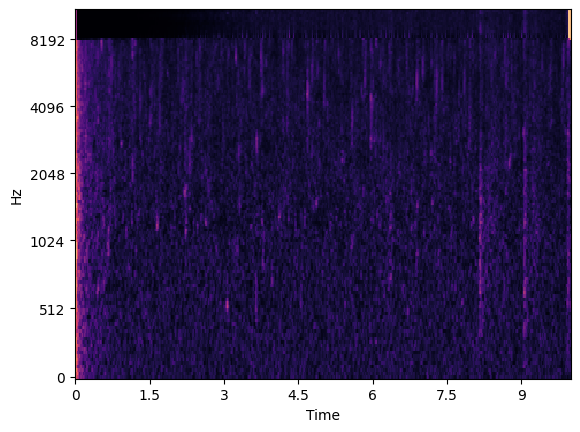

In [13]:
S = librosa.feature.melspectrogram(y=original_audio, sr=sr, power=1)
pcen_S = librosa.pcen(S * (2**31))

imgpcen = librosa.display.specshow(pcen_S, x_axis='time', y_axis='mel')

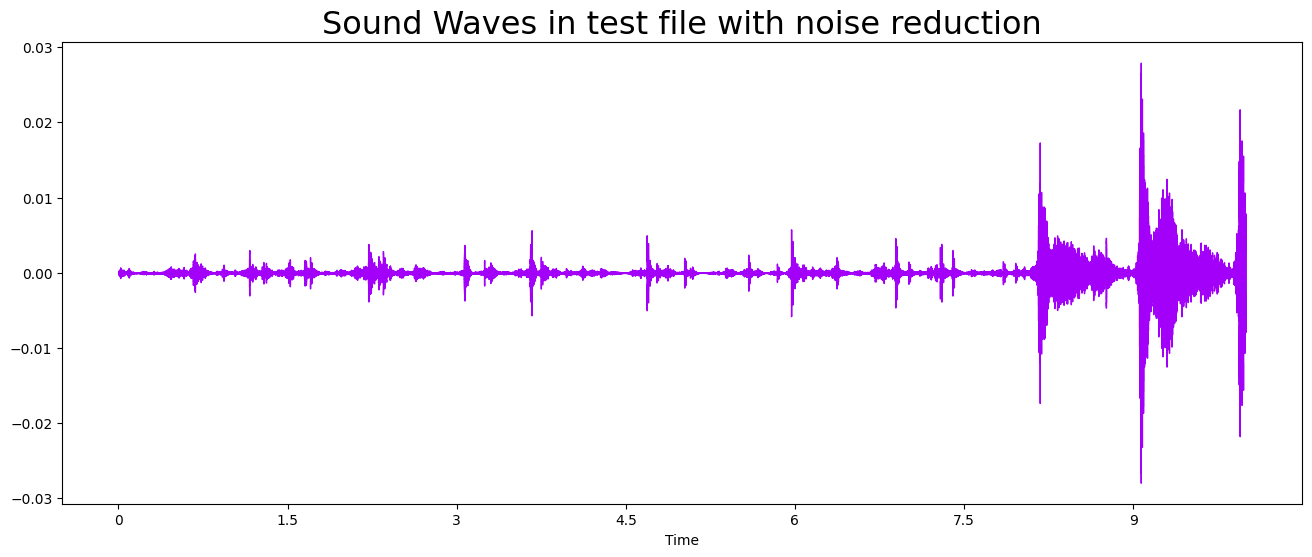

In [14]:
!pip3 install noisereduce
import noisereduce as nr

reduced_noise_audio = nr.reduce_noise(y=original_audio, sr=sr, stationary=True)

plt.figure(figsize = (16, 6))
librosa.display.waveshow(y = reduced_noise_audio, sr = sr, color = "#A300F9");
plt.title("Sound Waves in test file with noise reduction", fontsize = 23);
Audio(data=reduced_noise_audio, rate=sr)

**There is no point removing noise, since in a lot of cases, even the faintest sound tells us about the abnormality of the pump**

In [15]:
# zero crossings is the rate at which the signal changes from positive to negative or back.
zero_crossings = librosa.zero_crossings(original_audio, pad=False)
print(sum(zero_crossings))

19231


In [16]:
# Calculate the Spectral Centroids
spectral_centroids = librosa.feature.spectral_centroid(y=audio_file, sr=sr)[0]

# Shape is a vector
print('Centroids:', spectral_centroids, '\n')
print('Shape of Spectral Centroids:', spectral_centroids.shape, '\n')

# Computing the time variable for visualization
frames = range(len(spectral_centroids))

# Converts frame counts to time (seconds)
t = librosa.frames_to_time(frames)

print('frames:', frames, '\n')
print('t:', t)

# Function that normalizes the Sound Data
def normalize(x, axis=0):
    return minmax_scale(x, axis=axis)

Centroids: [1518.96252314 1559.63656678 1494.20138424 1619.21423869 1623.94623563
 1517.8092583  1532.88662483 1556.35348011 1589.59746122 1745.76703233
 1615.76300967 1617.62165962 1686.7276214  1654.25283039 1596.17321239
 1580.08506691 1545.21027432 1613.48724171 1599.62881913 1635.37498444
 1716.32872545 1567.75777224 1538.9359804  1610.52297846 1653.21294222
 1534.7058564  1530.8729427  1598.83698125 1506.70383798 1685.63376569
 1943.62150865 2070.73640558 2055.27207789 1837.36573922 1796.57601285
 1791.40967625 1616.3058239  1644.06442606 1730.33520148 1722.613016
 1844.60846152 1768.17343362 1651.35563992 1629.90894734 1580.86378947
 1700.46502143 1683.85254226 1727.81911086 1660.82074418 1868.08067185
 2139.41402127 2178.10864912 2013.09153471 1783.47466553 1636.39475724
 1451.886483   1787.5219694  1882.8382105  1637.18438816 1688.27754709
 1735.0378789  1661.5416338  1615.39173372 1517.88685533 1580.34896064
 1789.69119367 1843.39650114 1824.01590071 1791.22027777 1837.239665

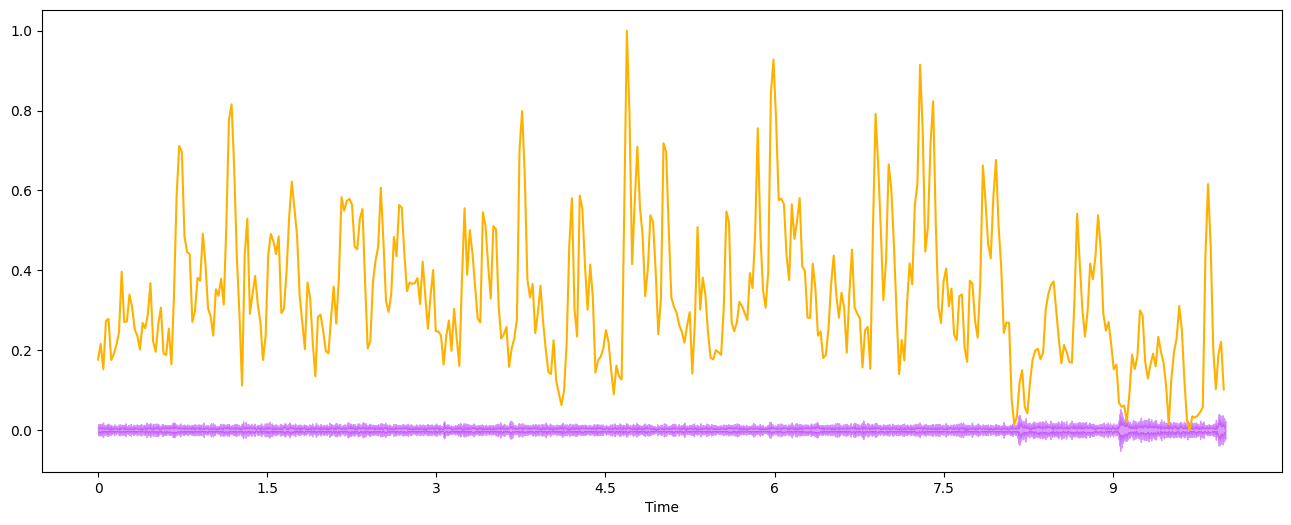

In [17]:
#Plotting the Spectral Centroid along the waveform
plt.figure(figsize = (16, 6))
librosa.display.waveshow(audio_file, sr=sr, alpha=0.4, color = '#A300F9');
plt.plot(t, normalize(spectral_centroids), color='#FFB100');

mfccs shape: (20, 431)


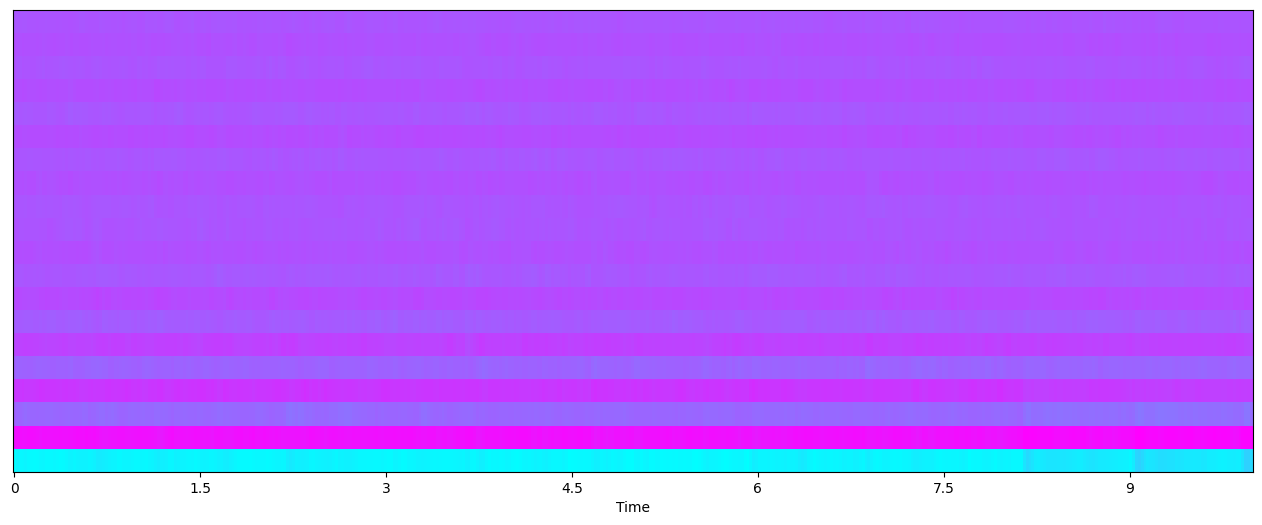

In [18]:
mfccs = librosa.feature.mfcc(y=audio_file, sr=sr)
print('mfccs shape:', mfccs.shape)

#Displaying  the MFCCs:
plt.figure(figsize = (16, 6))
librosa.display.specshow(mfccs, sr=sr, x_axis='time', cmap = 'cool');


**Few things that I noticed while reviewing the training data:**

**Abnormal audio files in most cases included Thuds, no sound of water, scraping, slow water flow.**

**Normal audio files however in most cases, included a more vivid sound of water flowing.**


In [19]:
# --- Helper Function for Feature Aggregation (FULL STATS) ---
def get_stats_full(data):
    """Calculates Mean, Variance, Skewness, and Kurtosis of a feature matrix."""
    if data.ndim == 1:
        data = np.expand_dims(data, axis=0)
    
    mean = np.mean(data, axis=1)
    variance = np.var(data, axis=1) 
    skewness = skew(data, axis=1) 
    kurt = kurtosis(data, axis=1)
    return mean, variance, skewness, kurt

# --- 1. Feature Extraction Function (UNCHANGED) ---
def extract_features(file_path):
    """Loads, normalizes, and extracts features for a single 10s file, segmented into 1s clips."""
    all_segment_features = []
    
    try:
        y, sr = librosa.load(file_path, sr=SAMPLE_RATE, duration=DURATION) 
        
        current_rms = np.sqrt(np.mean(y**2))
        if current_rms > 1e-6:
            y = y * (TARGET_RMS / current_rms)
        
        for start in range(0, len(y) - SEGMENT_SAMPLES + 1, HOP_SAMPLES):
            y_segment = y[start:start + SEGMENT_SAMPLES]
            
            if len(y_segment) < SEGMENT_SAMPLES:
                continue

            features_list = []
            
            # --- FEATURE EXTRACTION BLOCKS (UNCHANGED) ---
            
            # 1. RMS (Full Stats)
            rms = librosa.feature.rms(y=y_segment)
            rms_mean, rms_var, rms_skew, rms_kurt = get_stats_full(rms)
            features_list.extend(rms_mean); features_list.extend(rms_var); features_list.extend(rms_skew); features_list.extend(rms_kurt) 
            
            # 2. ZCR (Full Stats)
            zcr = librosa.feature.zero_crossing_rate(y=y_segment)
            zcr_mean, zcr_var, zcr_skew, zcr_kurt = get_stats_full(zcr)
            features_list.extend(zcr_mean); features_list.extend(zcr_var); features_list.extend(zcr_skew); features_list.extend(zcr_kurt) 
            
            # 3. Spectral Centroid (Full Stats)
            cent = librosa.feature.spectral_centroid(y=y_segment, sr=sr)
            cent_mean, cent_var, cent_skew, cent_kurt = get_stats_full(cent)
            features_list.extend(cent_mean); features_list.extend(cent_var); features_list.extend(cent_skew); features_list.extend(cent_kurt)
            
            # 4. Spectral Bandwidth (Full Stats)
            bw = librosa.feature.spectral_bandwidth(y=y_segment, sr=sr)
            bw_mean, bw_var, bw_skew, bw_kurt = get_stats_full(bw)
            features_list.extend(bw_mean); features_list.extend(bw_var); features_list.extend(bw_skew); features_list.extend(bw_kurt)

            # 5. Spectral Rolloff (Full Stats)
            rolloff = librosa.feature.spectral_rolloff(y=y_segment, sr=sr)
            rolloff_mean, rolloff_var, rolloff_skew, rolloff_kurt = get_stats_full(rolloff)
            features_list.extend(rolloff_mean); features_list.extend(rolloff_var); features_list.extend(rolloff_skew); features_list.extend(rolloff_kurt) 
            
            # 6. Spectral Flatness (Full Stats)
            flatness = librosa.feature.spectral_flatness(y=y_segment)
            flatness_mean, flatness_var, flatness_skew, flatness_kurt = get_stats_full(flatness)
            features_list.extend(flatness_mean); features_list.extend(flatness_var); features_list.extend(flatness_skew); features_list.extend(flatness_kurt)
            
            # 7. MFCCs Delta and Delta-Delta (Full Stats)
            mfccs = librosa.feature.mfcc(y=y_segment, sr=sr, n_mfcc=N_MFCC)
            mfccs_delta = librosa.feature.delta(mfccs)
            mfccs_delta2 = librosa.feature.delta(mfccs, order=2)

            for feature_set in [mfccs_delta, mfccs_delta2]: 
                mfccs_mean, mfccs_var, mfccs_skew, mfccs_kurt = get_stats_full(feature_set)
                features_list.extend(mfccs_mean); features_list.extend(mfccs_var); features_list.extend(mfccs_skew); features_list.extend(mfccs_kurt)

            # 8. Raw MFCCs (Mean/Var only)
            mfccs_mean, mfccs_var, _, _ = get_stats_full(mfccs)
            features_list.extend(mfccs_mean); features_list.extend(mfccs_var) 

            # 9. Chroma Features (Mean/Var only)
            chroma = librosa.feature.chroma_stft(y=y_segment, sr=sr)
            chroma_mean, chroma_var, _, _ = get_stats_full(chroma)
            features_list.extend(chroma_mean); features_list.extend(chroma_var)
            
            all_segment_features.append(np.array(features_list))

    except Exception as e:
        print(f"Error processing file {file_path}: {e}")
        return []
    
    return all_segment_features 


In [20]:
# --- 2. Data Loading and Feature Generation (UNCHANGED) ---
def load_data(data_dir):
    """Loads all training data and extracts features from segments."""
    X = []
    y = []
    
    normal_path = os.path.join(data_dir, 'train', 'normal')
    abnormal_path = os.path.join(data_dir, 'train', 'abnormal')
    
    if not os.path.exists(normal_path) or not os.path.exists(abnormal_path):
        print(f"Error: Could not find 'train/normal' or 'train/abnormal' in {data_dir}")
        return np.array(X), np.array(y)
    
    print("Processing Normal Audio Files (Segmenting)...")
    for filename in tqdm(os.listdir(normal_path)):
        if filename.endswith('.wav'):
            file_path = os.path.join(normal_path, filename)
            segment_features = extract_features(file_path)
            X.extend(segment_features)
            y.extend([0] * len(segment_features))
                
    print("Processing Abnormal Audio Files (Segmenting)...")
    for filename in tqdm(os.listdir(abnormal_path)):
        if filename.endswith('.wav'):
            file_path = os.path.join(abnormal_path, filename)
            segment_features = extract_features(file_path)
            X.extend(segment_features)
            y.extend([1] * len(segment_features))
                
    return np.array(X), np.array(y)


In [21]:
X_train_full, y_train_full = load_data(DATA_DIR)

Processing Normal Audio Files (Segmenting)...


100%|██████████| 457/457 [05:27<00:00,  1.39it/s]


Processing Abnormal Audio Files (Segmenting)...


100%|██████████| 165/165 [01:58<00:00,  1.39it/s]


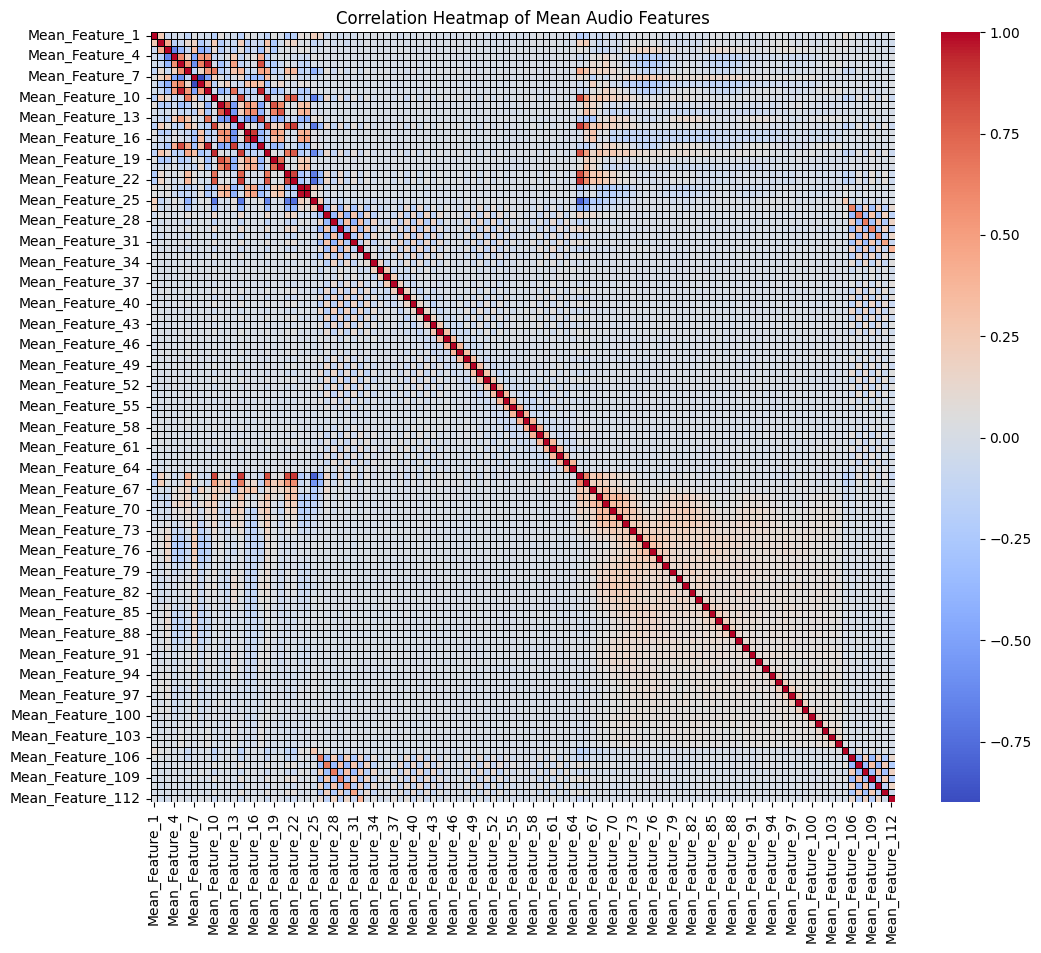


Highly Correlated Feature Pairs (r > 0.9):
Features that might be redundant: ['Mean_Feature_9', 'Mean_Feature_17', 'Mean_Feature_18', 'Mean_Feature_24']


In [22]:
total_features = X_train_full.shape[1]
num_stats = 4 # Mean, Var, Skew, Kurt

num_mean_features = total_features // num_stats # Total features divided by 4 statistics

X_means = X_train_full[:, :num_mean_features] 
feature_names = [f'Mean_Feature_{i+1}' for i in range(X_means.shape[1])]
df_means = pd.DataFrame(X_means, columns=feature_names)

corr_matrix = df_means.corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, cmap='coolwarm', linewidths=0.5, linecolor='black')
plt.title('Correlation Heatmap of Mean Audio Features')
plt.show()

print("\nHighly Correlated Feature Pairs (r > 0.9):")
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
to_drop = [column for column in upper.columns if any(upper[column] > 0.90)]
print(f"Features that might be redundant: {to_drop}")

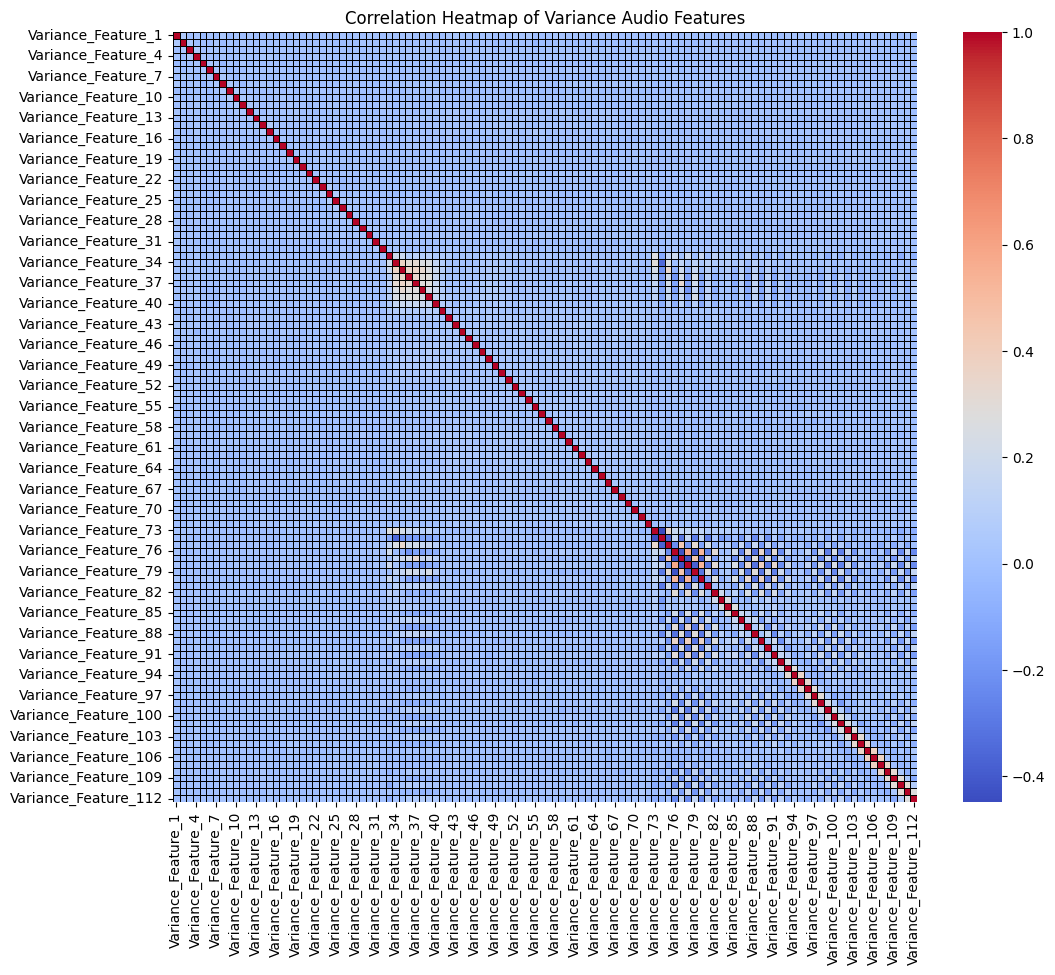


Highly Correlated Feature Pairs (r > 0.9):
Features that might be redundant: []


In [23]:
total_features = X_train_full.shape[1]
num_stats = 4 # Mean, Var, Skew, Kurt

num_var_features = total_features // num_stats # Total features divided by 4 statistics

start_index = num_mean_features  # Starts at the end of the Mean block
end_index = 2 * num_mean_features

X_var = X_train_full[:, start_index:end_index] 
feature_names = [f'Variance_Feature_{i+1}' for i in range(X_var.shape[1])]
df_var = pd.DataFrame(X_var, columns=feature_names)

corr_matrix = df_var.corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, cmap='coolwarm', linewidths=0.5, linecolor='black')
plt.title('Correlation Heatmap of Variance Audio Features')
plt.show()

print("\nHighly Correlated Feature Pairs (r > 0.9):")
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
to_drop = [column for column in upper.columns if any(upper[column] > 0.90)]
print(f"Features that might be redundant: {to_drop}")

In [24]:
def compare_and_train_models(X, y):

    # Scale the full dataset once
    scaler = StandardScaler()
    X_scaled_full = scaler.fit_transform(X)

    # --- Calculate Class Imbalance Weight ---
    count_neg = np.sum(y == 0)
    count_pos = np.sum(y == 1)
    scale_pos_weight = count_neg / count_pos

    models_dict = {
        "Logistic Regression (Reg)": LogisticRegression(solver='liblinear', random_state=42, C=10.0, penalty='l2', max_iter=1000),
        "K-Nearest Neighbors (KNN)": KNeighborsClassifier(n_neighbors=5), 
        "SVC (SVM)": SVC(kernel='rbf', probability=True, random_state=42, C=1.0), 
        "Random Forest (Weighted)": RandomForestClassifier(n_estimators=200, random_state=42, max_depth=10, min_samples_leaf=3, class_weight='balanced'),
        "AdaBoost (Tuned)": AdaBoostClassifier(n_estimators=100, learning_rate=0.5, random_state=42),
        "XGBoost (Weighted)": xgb.XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42, n_estimators=200, max_depth=5, learning_rate=0.1, scale_pos_weight=scale_pos_weight),
        "LightGBM (Weighted)": lgb.LGBMClassifier(random_state=42, n_estimators=200, max_depth=6, learning_rate=0.05, verbose=-1, scale_pos_weight=scale_pos_weight)
    }

    cv_results = {}
    best_avg_f1 = -1
    best_model_name = None
    
    N_SPLITS = 5
    skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=42)
    
    print(f"\n--- Running {N_SPLITS}-Fold Stratified Cross-Validation (Metric: F1-SCORE) ---")
    
    for name, model_template in models_dict.items():
        auc_scores = []
        acc_scores = []
        f1_scores = []
        
        is_scaled = any(substring in name for substring in ["Logistic Regression", "SVC", "KNN"])
        X_data = X_scaled_full if is_scaled else X
        
        print(f"Evaluating {name}...")
        
        for fold, (train_index, val_index) in enumerate(skf.split(X_data, y)):
            X_train_fold, X_val_fold = X_data[train_index], X_data[val_index]
            y_train_fold, y_val_fold = y[train_index], y[val_index]
            
            model = models_dict[name] 
            
            # Fit model (with sample weight for RF if applicable)
            if name == "Random Forest (Weighted)":
                sample_weights = np.where(y_train_fold == 1, scale_pos_weight, 1.0)
                model.fit(X_train_fold, y_train_fold, sample_weight=sample_weights)
            else:
                model.fit(X_train_fold, y_train_fold)
            
            y_val_pred = model.predict(X_val_fold)
            
            # Calculate F1-Score (Crucial metric for imbalanced data)
            f1_scores.append(f1_score(y_val_fold, y_val_pred))
            
            # Calculate Accuracy and AUC for context
            acc_scores.append(accuracy_score(y_val_fold, y_val_pred))
            if hasattr(model, 'predict_proba'):
                y_val_proba = model.predict_proba(X_val_fold)[:, 1]
                auc_scores.append(roc_auc_score(y_val_fold, y_val_proba))
        
        avg_f1 = np.mean(f1_scores)
        avg_acc = np.mean(acc_scores)
        avg_auc = np.mean(auc_scores) if auc_scores else 0.0

        cv_results[name] = {'F1': avg_f1, 'ACC': avg_acc, 'AUC': avg_auc, 'std_f1': np.std(f1_scores)}
        print(f"  -> Avg F1: {avg_f1:.4f} (+/- {np.std(f1_scores):.4f}) | Avg ACC: {avg_acc:.4f} | Avg AUC: {avg_auc:.4f}")

        # Track the best model based on F1-SCORE
        if avg_f1 > best_avg_f1:
            best_avg_f1 = avg_f1
            best_model_name = name
            

    print(f"\n✅ Retraining Best Model: {best_model_name} (based on F1-Score) on ALL data...")

    # Retrain the best model on the FULL dataset for final use
    best_model_template = models_dict[best_model_name]
    best_model = best_model_template
    is_scaled = any(substring in best_model_name for substring in ["Logistic Regression", "SVC", "KNN"])
    X_full_fit = X_scaled_full if is_scaled else X

    if best_model_name == "Random Forest (Weighted)":
        sample_weights = np.where(y == 1, scale_pos_weight, 1.0)
        best_model.fit(X_full_fit, y, sample_weight=sample_weights)
    else:
        best_model.fit(X_full_fit, y)


    return best_model, best_model_name, scaler


num_abnormal = np.sum(y_train_full)
total_segments = len(y_train_full)
print(f"Total segments created: {total_segments}")
print(f"Abnormal segments: {num_abnormal} ({num_abnormal/total_segments:.2%})")

best_model, best_model_name, best_scaler = compare_and_train_models(X_train_full, y_train_full)
        


Total segments created: 11818
Abnormal segments: 3135 (26.53%)

--- Running 5-Fold Stratified Cross-Validation (Metric: F1-SCORE) ---
Evaluating Logistic Regression (Reg)...
  -> Avg F1: 0.9168 (+/- 0.0045) | Avg ACC: 0.9563 | Avg AUC: 0.9886
Evaluating K-Nearest Neighbors (KNN)...
  -> Avg F1: 0.8242 (+/- 0.0085) | Avg ACC: 0.9143 | Avg AUC: 0.9541
Evaluating SVC (SVM)...
  -> Avg F1: 0.9019 (+/- 0.0120) | Avg ACC: 0.9523 | Avg AUC: 0.9874
Evaluating Random Forest (Weighted)...
  -> Avg F1: 0.9146 (+/- 0.0092) | Avg ACC: 0.9525 | Avg AUC: 0.9935
Evaluating AdaBoost (Tuned)...
  -> Avg F1: 0.9079 (+/- 0.0063) | Avg ACC: 0.9538 | Avg AUC: 0.9899
Evaluating XGBoost (Weighted)...
  -> Avg F1: 0.9835 (+/- 0.0051) | Avg ACC: 0.9913 | Avg AUC: 0.9996
Evaluating LightGBM (Weighted)...
  -> Avg F1: 0.9826 (+/- 0.0047) | Avg ACC: 0.9908 | Avg AUC: 0.9994

✅ Retraining Best Model: XGBoost (Weighted) (based on F1-Score) on ALL data...


In [25]:
# --- 4. Prediction Generation for Submission (UNCHANGED) ---
def create_submission(model, scaler, best_model_name, data_dir):

    VOTE_THRESHOLD_RATIO = 0.16
    
    test_path = os.path.join(data_dir, 'test')
    test_files = [f for f in os.listdir(test_path) if f.endswith('.wav')]
    test_files.sort()
    
    submission_results = []
    vote_ratio_analysis = []
    
    print("\nProcessing Test Audio Files for Final Submission (16% Vote)...")
    for filename in tqdm(test_files):
        file_path = os.path.join(test_path, filename)
        segment_features = extract_features(file_path)
        
        if not segment_features:
            final_label = 0
            
        else:
            X_test_segments = np.array(segment_features)
            
            # Apply scaling based on the best model selected
            is_scaled = any(substring in best_model_name for substring in ["Logistic Regression", "SVC", "KNN"])
            X_test_processed = scaler.transform(X_test_segments) if is_scaled else X_test_segments
            
            segment_labels = model.predict(X_test_processed)
            abnormal_count = np.sum(segment_labels)
            total_count = len(segment_labels)
            vote_ratio = abnormal_count / total_count
            
            # Final Label Decision (using the 30% threshold)
            if vote_ratio >= VOTE_THRESHOLD_RATIO:
                final_label = 1
            else:
                final_label = 0
                
        # Only append filename and the final label
        submission_results.append({
            'file_name': filename,
            'target': final_label 
        })

        vote_ratio_analysis.append({
            'file_name' : filename,
            'target' : final_label,
            'vote_ratio' : vote_ratio
        })
    
    submission_df = pd.DataFrame(submission_results)
    vote_r = pd.DataFrame(vote_ratio_analysis)
    
    # Save the file with only filename and label
    final_output_name = 'final_submission.csv'
    submission_df.to_csv(final_output_name, index=False)
    vote_r.to_csv('vote_ratio_analysis.csv', index=False)
    print(f"\n✅ Final submission file '{final_output_name}' created (2 columns).")


create_submission(best_model, best_scaler, best_model_name, DATA_DIR)



Processing Test Audio Files for Final Submission (16% Vote)...


100%|██████████| 156/156 [01:55<00:00,  1.35it/s]


✅ Final submission file 'final_submission.csv' created (2 columns).
